In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

data_path = "/kaggle/input/datasets/vaukaofworlds/thecycloneimagedataset"
print("Dataset files:", os.listdir(data_path))


TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Dataset files: ['Cyclone_Labels h5.npy', 'Cyclone_Images.h5']


In [2]:

import os
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = "/kaggle/input/datasets/vaukaofworlds/thecycloneimagedataset"
IMG_PATH = os.path.join(DATA_PATH, "Cyclone_Images.h5")
LABEL_PATH = os.path.join(DATA_PATH, "Cyclone_Labels h5.npy")

# Load labels
labels = np.load(LABEL_PATH, allow_pickle=True)
df = pd.DataFrame(labels, columns=[
    "basin", "cyclone_id", "longitude", "latitude",
    "timestamp", "wind_knots", "size", "pressure_hpa"
])

# Load images
with h5py.File(IMG_PATH, "r") as f:
    X = f["Images"][:]

X = X.astype(np.float32) / 255.0
y = pd.to_numeric(df["wind_knots"], errors="coerce").to_numpy(
    dtype=np.float32
)
groups_all = df["cyclone_id"].astype(str).to_numpy()

# Repair invalid values in channel 3
bad_images = np.where(~np.isfinite(X).all(axis=(1, 2, 3)))[0]
fully_corrupted_channels = []

for i in bad_images:
    channel = X[i, :, :, 3]
    invalid = ~np.isfinite(channel)
    valid = channel[np.isfinite(channel)]

    if valid.size == 0:
        fully_corrupted_channels.append(i)
        channel[:] = 0.0
    else:
        channel[invalid] = np.median(valid)

    X[i, :, :, 3] = channel

# Exclude completely corrupted fourth channels
keep = np.ones(len(X), dtype=bool)
keep[np.array(fully_corrupted_channels, dtype=int)] = False

X_clean = X[keep]
df_clean = df.iloc[np.where(keep)[0]].reset_index(drop=True)
y_clean = y[keep]
groups = groups_all[keep]

assert np.isfinite(X_clean).all()
assert np.isfinite(y_clean).all()

# Test split: 20% of cyclone IDs
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)
trainval_idx, test_idx = next(
    split1.split(X_clean, y_clean, groups=groups)
)

# Validation split: 20% of the remaining cyclone IDs
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED + 1
)
train_rel, val_rel = next(
    split2.split(
        X_clean[trainval_idx],
        y_clean[trainval_idx],
        groups=groups[trainval_idx]
    )
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

X_train, y_train = X_clean[train_idx], y_clean[train_idx]
X_val, y_val = X_clean[val_idx], y_clean[val_idx]
X_test, y_test = X_clean[test_idx], y_clean[test_idx]

train_ids = set(groups[train_idx])
val_ids = set(groups[val_idx])
test_ids = set(groups[test_idx])

print("Train:", X_train.shape, "| cyclones:", len(train_ids))
print("Validation:", X_val.shape, "| cyclones:", len(val_ids))
print("Test:", X_test.shape, "| cyclones:", len(test_ids))
print("Cyclone overlap:",
      len(train_ids & val_ids) +
      len(train_ids & test_ids) +
      len(val_ids & test_ids))
print("Non-finite values:", int((~np.isfinite(X_clean)).sum()))


Train: (13176, 128, 128, 4) | cyclones: 310
Validation: (3660, 128, 128, 4) | cyclones: 78
Test: (4228, 128, 128, 4) | cyclones: 97
Cyclone overlap: 0
Non-finite values: 0


In [3]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(4096, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

model = models.Sequential([
    layers.Input(shape=(128, 128, 4)),

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(192, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, name="predicted_wind_knots")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae"),
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_mae",
        patience=4,
        mode="min",
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae",
        factor=0.5,
        patience=2,
        mode="min",
        min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_cyclone_cnn.keras",
        monitor="val_mae",
        mode="min",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


I0000 00:00:1792166020.552324      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792166020.556498      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 192)    │       221,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 192)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicted_wind_knots (Dense)    │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 340,993 (1.30 MB)

 Trainable params: 340,161 (1.30 MB)

 Non-trainable params: 832 (3.25 KB)

Epoch 1/20
  5/412 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - loss: 3075.7825 - mae: 47.9495 - rmse: 55.4434  

I0000 00:00:1792166043.639363     144 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


412/412 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step - loss: 694.0689 - mae: 19.5128 - rmse: 26.3452 - val_loss: 754.3622 - val_mae: 19.7935 - val_rmse: 27.4657 - learning_rate: 0.0010
Epoch 2/20
412/412 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - loss: 484.8192 - mae: 16.4678 - rmse: 22.0186 - val_loss: 528.6542 - val_mae: 16.8141 - val_rmse: 22.9925 - learning_rate: 0.0010
Epoch 3/20
412/412 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - loss: 459.2516 - mae: 16.0316 - rmse: 21.4302 - val_loss: 526.5858 - val_mae: 17.0099 - val_rmse: 22.9475 - learning_rate: 0.0010
Epoch 4/20
412/412 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - loss: 441.4171 - mae: 15.7528 - rmse: 21.0099 - val_loss: 671.1957 - val_mae: 18.4370 - val_rmse: 25.9074 - learning_rate: 0.0010
Epoch 5/20
412/412 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - loss: 404.3184 - mae: 15.0215 - rmse: 20.1077 - val_loss: 520.4526 - val_mae: 16.3083 - val_rmse: 22.8134 - learning_rate: 5.0000e-04
Epoch 6/20
412/412 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 382.0937 - mae:

In [4]:

print("Best validation MAE:",
      min(history.history["val_mae"]), "knots")

print("Best validation MAE epoch:",
      int(np.argmin(history.history["val_mae"]) + 1))

print("Best validation RMSE:",
      min(history.history["val_rmse"]), "knots")


Best validation MAE: 15.265310287475586 knots
Best validation MAE epoch: 7
Best validation RMSE: 20.351863861083984 knots


133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
=== CNN TEST RESULTS ===
Test MAE:  14.90 knots
Test RMSE: 19.94 knots

=== MEDIAN BASELINE ===
Baseline prediction: 42.50 knots
Baseline MAE:  22.65 knots
Baseline RMSE: 31.71 knots

Example predictions:
Actual:   25.0 | Predicted:   29.1 knots
Actual:   25.0 | Predicted:   26.5 knots
Actual:   25.0 | Predicted:   23.8 knots
Actual:   28.0 | Predicted:   29.4 knots
Actual:   30.0 | Predicted:   25.4 knots
Actual:   20.0 | Predicted:   31.6 knots
Actual:   18.0 | Predicted:   34.6 knots
Actual:   15.0 | Predicted:   24.0 knots
Actual:   15.0 | Predicted:   26.3 knots
Actual:   15.0 | Predicted:   29.0 knots


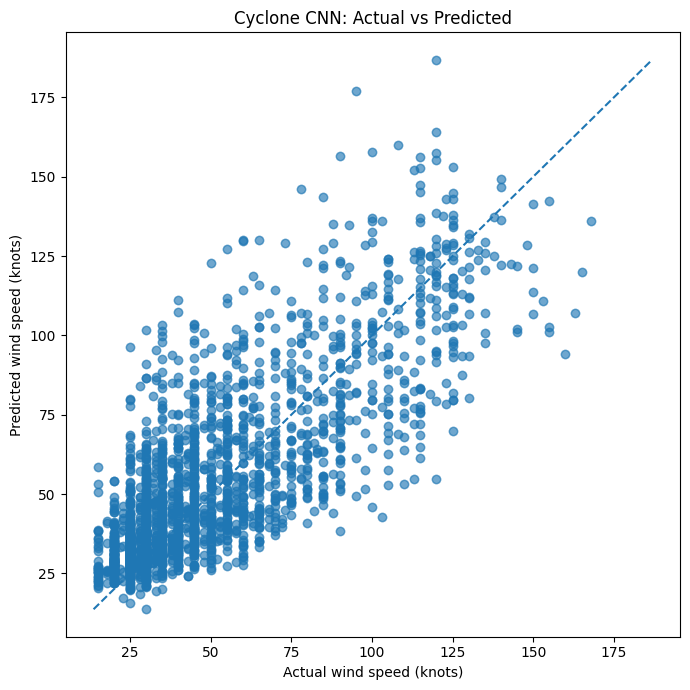

In [5]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Load the checkpoint with the best validation MAE
best_model = tf.keras.models.load_model(
    "/kaggle/working/best_cyclone_cnn.keras"
)

# Evaluate on unseen cyclone IDs
predictions = best_model.predict(X_test, batch_size=32, verbose=1).ravel()

test_mae = mean_absolute_error(y_test, predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Simple baseline: always predict the training-set median wind speed
baseline_prediction = float(np.median(y_train))
baseline_preds = np.full_like(y_test, baseline_prediction)

baseline_mae = mean_absolute_error(y_test, baseline_preds)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_preds))

print("=== CNN TEST RESULTS ===")
print(f"Test MAE:  {test_mae:.2f} knots")
print(f"Test RMSE: {test_rmse:.2f} knots")

print("\n=== MEDIAN BASELINE ===")
print(f"Baseline prediction: {baseline_prediction:.2f} knots")
print(f"Baseline MAE:  {baseline_mae:.2f} knots")
print(f"Baseline RMSE: {baseline_rmse:.2f} knots")

print("\nExample predictions:")
for actual, predicted in zip(y_test[:10], predictions[:10]):
    print(f"Actual: {actual:6.1f} | Predicted: {predicted:6.1f} knots")

plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions, alpha=0.4)
low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual wind speed (knots)")
plt.ylabel("Predicted wind speed (knots)")
plt.title("Cyclone CNN: Actual vs Predicted")
plt.tight_layout()
plt.show()


In [6]:

import numpy as np
import pandas as pd

actual = np.asarray(y_test).ravel()
predicted = np.asarray(predictions).ravel()

results = pd.DataFrame({
    "Actual wind (knots)": actual,
    "Predicted wind (knots)": predicted,
})

results["Absolute error (knots)"] = np.abs(
    results["Actual wind (knots)"] -
    results["Predicted wind (knots)"]
)

results["Wind category"] = pd.cut(
    results["Actual wind (knots)"],
    bins=[-np.inf, 33, 63, 95, 200, np.inf],
    labels=[
        "Below 34",
        "34–63",
        "64–95",
        "96–200",
        "Above 200"
    ],
    right=False
)

print("Performance by actual wind-speed range:")
print(
    results.groupby("Wind category", observed=False)
    .agg(
        samples=("Absolute error (knots)", "size"),
        MAE=("Absolute error (knots)", "mean"),
        mean_actual=("Actual wind (knots)", "mean"),
        mean_predicted=("Predicted wind (knots)", "mean")
    )
    .round(2)
)


Performance by actual wind-speed range:
               samples        MAE  mean_actual  mean_predicted
Wind category                                                 
Below 34          1470  11.070000    25.540001       35.669998
34–63             1624  14.440000    45.029999       51.360001
64–95              630  19.360001    76.489998       70.940002
96–200             504  21.969999   116.769997      105.730003
Above 200            0        NaN          NaN             NaN


In [7]:

from sklearn.metrics import r2_score
import numpy as np

errors = predictions - np.asarray(y_test).ravel()

print(f"Mean signed error: {np.mean(errors):.2f} knots")
print(f"Prediction correlation: {np.corrcoef(y_test.ravel(), predictions)[0, 1]:.3f}")
print(f"Test R²: {r2_score(y_test.ravel(), predictions):.3f}")

print("\nInterpretation:")
print("Positive signed error = overprediction on average")
print("Negative signed error = underprediction on average")


Mean signed error: 3.81 knots
Prediction correlation: 0.783
Test R²: 0.570

Interpretation:
Positive signed error = overprediction on average
Negative signed error = underprediction on average


In [8]:

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

# Keep the original model safe.
checkpoint_path = "/kaggle/working/best_cyclone_cnn_huber.keras"

# Build a fresh CNN with the same general architecture.
inputs = keras.Input(shape=(128, 128, 4))

x = layers.Conv2D(32, 3, padding="same", use_bias=False)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(192, 3, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1)(x)

model_huber = keras.Model(inputs, outputs)

model_huber.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.Huber(delta=10.0),
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae"),
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_mae",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_mae",
        patience=6,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_mae",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode="min",
        verbose=1
    )
]

history_huber = model_huber.fit(
    X_train,
    np.asarray(y_train).ravel(),
    validation_data=(X_val, np.asarray(y_val).ravel()),
    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/30
412/412 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 265.2283 - mae: 31.1134 - rmse: 41.0320
Epoch 1: val_mae improved from None to 20.21151, saving model to /kaggle/working/best_cyclone_cnn_huber.keras

Epoch 1: finished saving model to /kaggle/working/best_cyclone_cnn_huber.keras
412/412 ━━━━━━━━━━━━━━━━━━━━ 22s 42ms/step - loss: 182.7484 - mae: 22.6294 - rmse: 32.2772 - val_loss: 160.0323 - val_mae: 20.2115 - val_rmse: 28.9276 - learning_rate: 3.0000e-04
Epoch 2/30
410/412 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 121.4027 - mae: 16.3523 - rmse: 22.6485
Epoch 2: val_mae improved from 20.21151 to 18.11196, saving model to /kaggle/working/best_cyclone_cnn_huber.keras

Epoch 2: finished saving model to /kaggle/working/best_cyclone_cnn_huber.keras
412/412 ━━━━━━━━━━━━━━━━━━━━ 12s 28ms/step - loss: 119.7014 - mae: 16.1632 - rmse: 22.4880 - val_loss: 139.4646 - val_mae: 18.1120 - val_rmse: 25.9693 - learning_rate: 3.0000e-04
Epoch 3/30
410/412 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - l

In [9]:

import numpy as np

best_epoch = int(np.argmin(history_huber.history["val_mae"]) + 1)
best_val_mae = float(np.min(history_huber.history["val_mae"]))

print(f"Best validation MAE: {best_val_mae:.2f} knots")
print(f"Best epoch: {best_epoch}")
print(f"Saved checkpoint: {checkpoint_path}")



Best validation MAE: 12.01 knots
Best epoch: 18
Saved checkpoint: /kaggle/working/best_cyclone_cnn_huber.keras


In [10]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the best Huber checkpoint saved during training
best_huber = tf.keras.models.load_model(
    "/kaggle/working/best_cyclone_cnn_huber.keras"
)

actual = np.asarray(y_test).ravel()

huber_predictions = best_huber.predict(
    X_test, batch_size=32, verbose=1
).ravel()

huber_mae = mean_absolute_error(actual, huber_predictions)
huber_rmse = np.sqrt(mean_squared_error(actual, huber_predictions))

print("=== IMPROVED HUBER CNN ===")
print(f"Test MAE:  {huber_mae:.2f} knots")
print(f"Test RMSE: {huber_rmse:.2f} knots")

print("\n=== ORIGINAL CNN ===")
print("Test MAE:  14.90 knots")
print("Test RMSE: 19.94 knots")

print("\n=== CHANGE IN TEST MAE ===")
print(f"{(14.90 - huber_mae) / 14.90 * 100:.1f}% reduction")

print("\n=== CHANGE IN TEST RMSE ===")
print(f"{(19.94 - huber_rmse) / 19.94 * 100:.1f}% reduction")


133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
=== IMPROVED HUBER CNN ===
Test MAE:  11.75 knots
Test RMSE: 16.32 knots

=== ORIGINAL CNN ===
Test MAE:  14.90 knots
Test RMSE: 19.94 knots

=== CHANGE IN TEST MAE ===
21.1% reduction

=== CHANGE IN TEST RMSE ===
18.2% reduction


In [11]:

import os
import tensorflow as tf

model_path = "/kaggle/working/best_cyclone_cnn_huber.keras"

# Load the best checkpoint (best validation MAE)
best_huber = tf.keras.models.load_model(model_path)

# Save the final model explicitly
best_huber.save(model_path)

# Verify that the file exists
print("Model saved:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")
print("Model input shape:", best_huber.input_shape)
print("Model output shape:", best_huber.output_shape)


Model saved: True
File size: 3.98 MB
Model input shape: (None, 128, 128, 4)
Model output shape: (None, 1)


In [12]:

from IPython.display import FileLink, display

display(FileLink(
    "/kaggle/working/best_cyclone_cnn_huber.keras"
))


/kaggle/working/best_cyclone_cnn_huber.keras

In [13]:

import os

path = "/kaggle/working/best_cyclone_cnn_huber.keras"

print("Exists:", os.path.isfile(path))
if os.path.isfile(path):
    print("Size:", round(os.path.getsize(path) / (1024**2), 2), "MB")
else:
    print("Check that training and checkpoint saving completed.")


Exists: True
Size: 3.98 MB
